In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
import estraces
import scared
plt.rcParams['figure.figsize'] = (20, 5)

# 数据集信息

该数据集的采集信息如下：

- 目标设备：ChipWhisperer308 mainboard + [ATXmega128D4-AU (AVR架构)](https://rtfm.newae.com/Targets/UFO%20Targets/CW308T-XMEGA/)

- 目标设备运行频率：7.37Mhz

- 示波器：[CW1200 ChipWhisperer-Pro](https://rtfm.newae.com/Capture/ChipWhisperer-Pro/)

- 采样率：目标运行频率的4倍。

- 目标实现：RSA-1024([avr-crypto-lib库实现](https://github.com/newaetech/chipwhisperer/tree/develop/firmware/mcu/crypto/avrcryptolib/rsa))

- 曲线长度：54700

- 16比特密钥：[0x8A, 0xB0]

由于ATXmega128D4-AU芯片执行RSA加密速度慢且示波器的存储深度有限，<span style="color:red">只进行了16比特的RSA加密测试</span>。

In [ ]:
ths = estraces.read_ths_from_ets_file("rsa1024-xmega-single-trace.ets")
print(ths[0])
trace = ths.samples[:][0]

# 曲线观察

In [ ]:
plt.plot(trace)

- 如果密钥是0：只有平方操作
- 如果密钥是1：平方操作+乘法操作

能量迹中多处呈现规律的高能量峰值。这些能量峰值有两种宽度，如果密钥是0，则峰值宽度较小，如果密钥是1则宽度大。利用这一点，我们可以手动的辨别0和1。

二进制形式如下图所示：

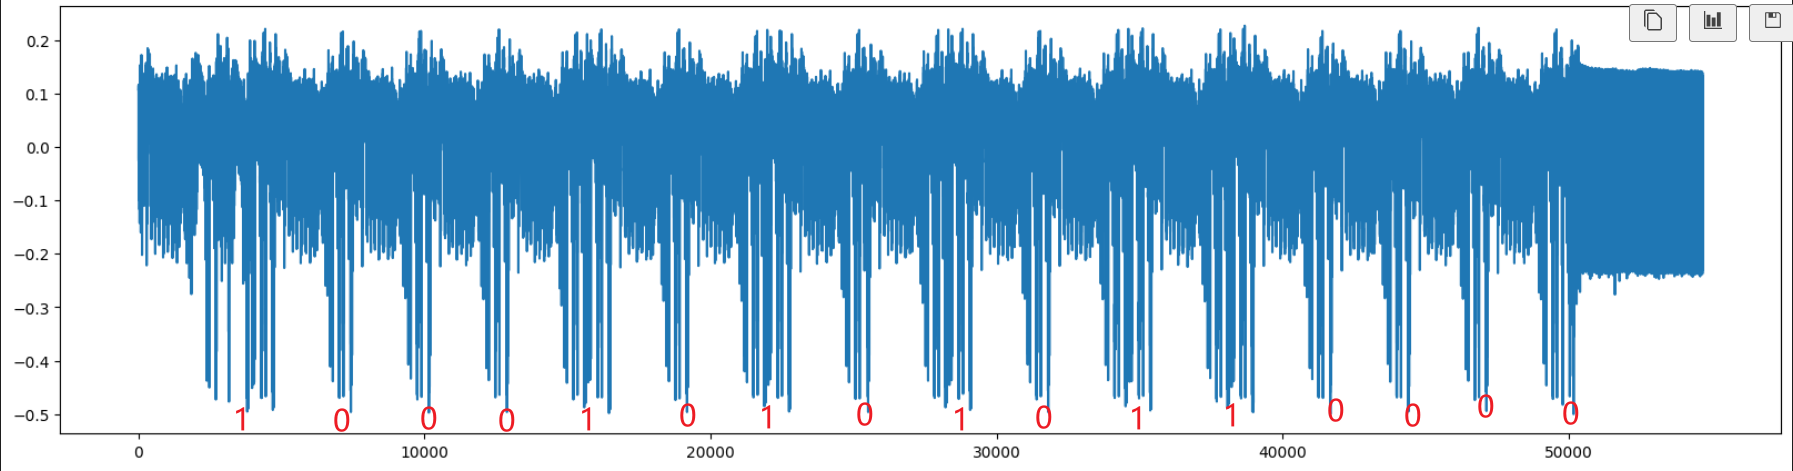

# 模式匹配

我们可以清楚的找到平方操作的波形（如下所示）

In [ ]:
plt.plot(trace);
plt.axvline(6500, color="red");
plt.axvline(7500, color="red");

可以用绝对差值和（Sum of Absolute Differences, SAD）和相关系数等统计工具结合滑动窗口来找到所有平方操作，步骤如下：

1. 首先确定参考波形ref_trace：RSA中任意一个平方波形均可。
2. 设置滑动窗口大小为len(ref_trace)，滑动步长为1
3. 计算滑动窗口与参考波形的SAD或相关系数

In [ ]:
start, end = 6500, 7500
rsa_square = ths.samples[0][start:end]
trace =  ths.samples[0]
corrs = []
SADs = []
for i in range(0, len(trace)-len(rsa_square), 1):
    window = trace[i:(i+len(rsa_square))]
    SADs.append(np.sum(abs(window - rsa_square)))
    corrs.append(np.corrcoef(window, rsa_square)[0,1])

corrs = np.array(corrs)
SADs = np.array(SADs)
plt.figure()
plt.plot(SADs)
plt.title('SAD Match for RSA')
plt.ylabel('SAD Difference')
plt.xlabel('Points')

plt.figure()
plt.plot(corrs)
plt.title('Correlation Match for RSA')
plt.ylabel('Correlation')
plt.xlabel('Points');

无论是SAD还是相关系数，可以发现除了触发开始和触发结束位置的值较小（收到触发的能量影响），其他位置的平方操作匹配度都很高。
此外，平方操作和乘法操作在SAD和相关系数两个指标上有一定的关系（其值小于平方操作）。

# 密钥恢复（以SAD为例）

首先，对SAD数据进行尖峰检测，识别出所有平方和乘法操作。根据下面的规则，判断密钥是1还是0。
- 如果密钥是1：平方操作后面紧接着一个乘法操作，因此当前尖峰与下一个尖峰之间的距离略短。
- 如果密钥是0：则平方操作后面无乘法操作，当前尖峰和下一个尖峰之间的距离更大一些。

In [ ]:
# 尖峰检测
times = scared.signal_processing.peaks_detection.find_peaks(-SADs, min_peak_distance=100, min_peak_height=-65)
times = np.array(times, dtype=np.int32)
print(times)
plt.scatter(times, -SADs[times], marker="+", color="red", s=100)
plt.plot(-SADs)
plt.axhline(-65, color="red", linestyle="--", label="Threshold")
plt.legend();

In [ ]:
# 密钥恢复
"""
如果密钥是1：当前尖峰与下一个尖峰的距离为大约是852（第一个1为1600）
如果密钥是0：当前尖峰与下一个尖峰的距离为约是2782
因此可以将阈值设置为2000。
"""
guess_key = ""
threshold = 2000
i = 0
while (i < len(times)-1):
    diff = times[i+1] - times[i]
    print(diff)
    if (diff < threshold):
        guess_key += "1"
        i += 2
    else:
        guess_key += "0"
        i += 1
guess_key += "1" if times[-1] - times[-2] < 2000 else "0"

print(f"16比特密钥的二进制形式={guess_key}")
print(f"16比特密钥的十六进制形式={hex(int(guess_key, 2))}")

# 参考

- [ChipWhisper-PA_SPA_2-RSA_on_XMEGA_8bit](https://github.com/newaetech/chipwhisperer-jupyter/blob/84022bf6354b3e427542f5b15e606370bf167cc5/courses/sca202/PA_SPA_2-RSA_on_XMEGA_8bit.ipynb)